# Camera Ground Truth Tracking

This notebook demonstrates how to extract 2D ground truth from your camera using homography transformation.

## Overview

Your tilted-down camera view is perfect for homography-based ground plane tracking:

1. **Calibration**: Define correspondence between image pixels and real-world ground coordinates
2. **Tracking**: Detect TX device in each frame
3. **Transform**: Convert pixel positions to metric XY coordinates

The floor tiles in your images are ideal calibration references!

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Add parent directory to path
sys.path.append(str(Path.cwd().parent))

from camera_tracking import (
    HomographyCalibrator,
    HomographyCalibration,
    TXTracker,
    visualize_tracking_results
)
from session_data import SessionData

print("✓ Modules loaded successfully!")

✓ Modules loaded successfully!


## Step 1: Load Session Data

Load your session containing camera images.

In [2]:
# Configure your session path
session_dir = Path("../../data/2025-11-25/session_122307")
session = SessionData.from_directory(session_dir)

print(session.summary())

# Get image paths
image_paths = session.get_image_paths()
print(f"\nFound {len(image_paths)} images")

Session: session_122307
Start: 2025-11-25 12:23:07.121257
End: 2025-11-25 13:08:46.030869
Duration: 2738.9 seconds
Total Samples: 112
Data Points: 112
Data Points with FTM: 0
Images: 112


Found 112 images


## Step 2: Display Calibration Image

Look at your camera image and identify reference points on the ground plane.

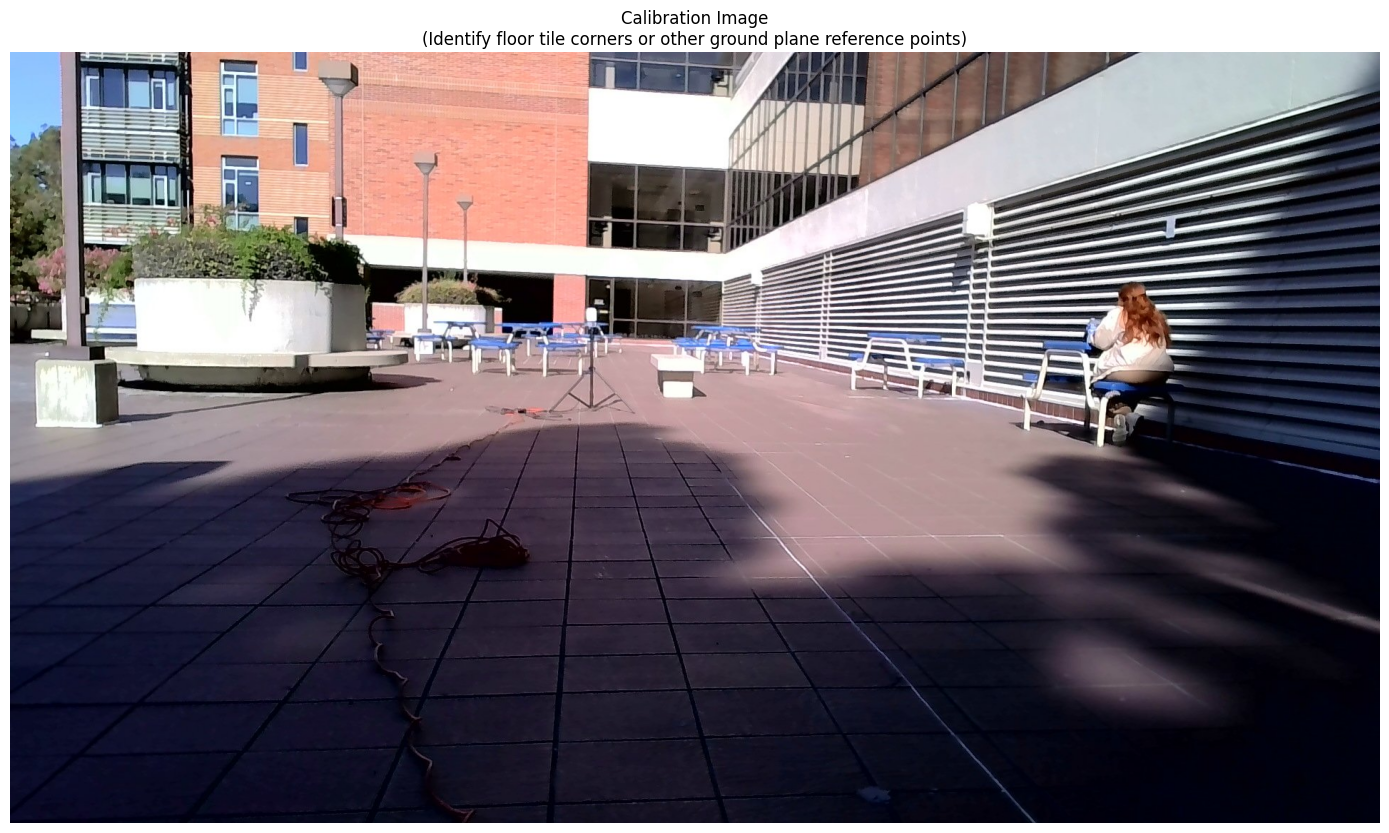

Image size: 1920 x 1080 pixels


In [10]:
# Use first image for calibration
calibration_image_path = image_paths[0]
img = cv2.imread(str(calibration_image_path))
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(14, 10))
plt.imshow(img_rgb)
plt.title('Calibration Image\n(Identify floor tile corners or other ground plane reference points)')
plt.axis('off')
plt.tight_layout()
plt.show()

print(f"Image size: {img_rgb.shape[1]} x {img_rgb.shape[0]} pixels")

## Step 3: Define Calibration Points

**Instructions:**

1. Look at the image above and identify 4+ points on the ground plane
2. Use floor tiles as reference (they're a perfect grid!)
3. For each point, note:
   - Pixel coordinates (x, y) in the image
   - Real-world coordinates (x, y) in meters

**Tips:**
- Use tile corners as reference points
- If tiles are square (e.g., 30cm × 30cm), use that as your metric scale
- Define a coordinate system: e.g., bottom-left corner = (0, 0), X=right, Y=forward
- More points = better accuracy (4 minimum, 6-8 recommended)

Image points (pixels):
  P0: (210, 944)
  P1: (1598, 925)
  P2: (1069, 551)
  P3: (631, 553)

World points (meters):
  P0: (0.00, 0.00)
  P1: (7.00, 0.00)
  P2: (7.00, 14.00)
  P3: (0.00, 14.00)


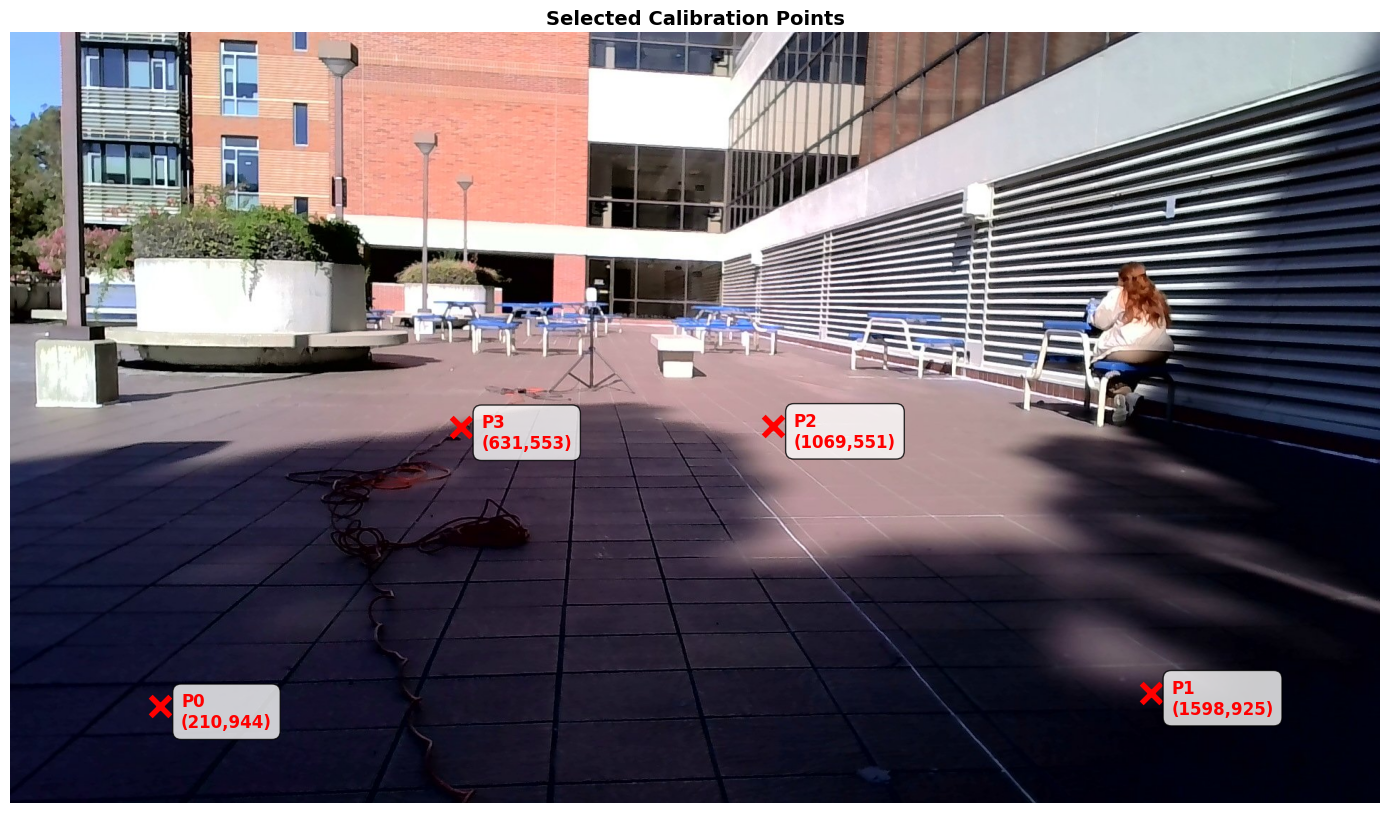

In [12]:
# REPLACE THESE WITH YOUR ACTUAL MEASUREMENTS!
# Format: [x_pixel, y_pixel]

image_points = np.array([
    [210, 944],   # Point 0: bottom-left tile corner
    [1598, 925],   # Point 1: bottom-right tile corner
    [1069, 551],   # Point 2: top-right tile corner
    [631, 553],   # Point 3: top-left tile corner
], dtype=np.float32)

# REPLACE THESE WITH YOUR ACTUAL MEASUREMENTS!
# Format: [x_meters, y_meters]
# Example: if tiles are 0.5m x 0.5m, and you pick 4 corners forming a 2m x 2m square
world_points = np.array([
    [0.0, 0.0],   # Point 0: origin (bottom-left)
    [7.0, 0.0],   # Point 1: 2 meters to the right
    [7.0, 14.0],   # Point 2: 2m right, 2.5m forward
    [0.0, 14.0],   # Point 3: 2.5 meters forward
], dtype=np.float32)

print("Image points (pixels):")
for i, pt in enumerate(image_points):
    print(f"  P{i}: ({pt[0]:.0f}, {pt[1]:.0f})")

print("\nWorld points (meters):")
for i, pt in enumerate(world_points):
    print(f"  P{i}: ({pt[0]:.2f}, {pt[1]:.2f})")

# Visualize the points
plt.figure(figsize=(14, 10))
plt.imshow(img_rgb)
plt.scatter(image_points[:, 0], image_points[:, 1], c='red', s=200, marker='x', linewidths=4)
for i, (x, y) in enumerate(image_points):
    plt.annotate(f'P{i}\n({x:.0f},{y:.0f})', (x, y), 
                xytext=(15, -15), textcoords='offset points',
                color='red', fontsize=12, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8))
plt.title('Selected Calibration Points', fontsize=14, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

## Step 4: Compute Homography

Calculate the transformation matrix from image to world coordinates.

In [13]:
# Create calibrator
calibrator = HomographyCalibrator(calibration_image_path)

# Compute homography
calibration = calibrator.calibrate(image_points, world_points)

# Visualize calibration quality
save_path = session.get_save_plot_path() / 'homography_calibration.png'
calibrator.visualize_calibration(calibration, save_path=save_path)

# Save calibration
calib_file = session.session_dir / 'camera_calibration.json'
calibration.save(calib_file)

print(f"\n✓ Calibration complete!")
print(f"  Saved to: {calib_file}")


Calibration complete!
Reprojection RMSE: 0.0000 meters
Saved calibration visualization to: ../../data/2025-11-25/session_122307/plots/homography_calibration.png
Saved calibration to: ../../data/2025-11-25/session_122307/camera_calibration.json

✓ Calibration complete!
  Saved to: ../../data/2025-11-25/session_122307/camera_calibration.json


## Step 5: Test the Calibration

Click on a point in the image to see its world coordinates.

In [14]:
# Test a few points
test_points = np.array([
    [640, 360],  # Center of image
    [400, 300],  # Example point
    [800, 400],  # Example point
])

world_coords = calibration.pixel_to_world(test_points)

print("Test Points:")
print("-" * 50)
for i, (pixel, world) in enumerate(zip(test_points, world_coords)):
    print(f"Pixel ({pixel[0]:.0f}, {pixel[1]:.0f}) -> "
          f"World ({world[0]:.3f}m, {world[1]:.3f}m)")

Test Points:
--------------------------------------------------
Pixel (640, 360) -> World (34.691m, -230.656m)
Pixel (400, 300) -> World (18.573m, -54.107m)
Pixel (800, 400) -> World (0.500m, 143.850m)


## Step 6: Track TX Device

Now track the TX position across all frames using blob detection.

In [18]:
# Create tracker
tracker = TXTracker(calibration)
tracker.tracking_method = 'blob'

print("Tracking TX device using blob detection...")
print("This works well for white/bright rectangular objects.\n")

# Track across all images
tracking_results = tracker.track_session(
    image_paths,
    min_area=80,      # Adjust based on TX size
    max_area=300,    # Adjust based on TX size
    save_path=session.session_dir / 'tracking_results.json'
)

print(f"\n✓ Tracking complete!")
print(f"  Detection rate: {tracking_results['detection_rate']*100:.1f}%")
print(f"  Detected in {np.sum(tracking_results['detected'])}/{len(image_paths)} frames")

Tracking TX device using blob detection...
This works well for white/bright rectangular objects.


Tracking TX across 112 images...
Processed 10/112 images
Processed 20/112 images
Processed 30/112 images
Processed 40/112 images
Processed 50/112 images
Processed 60/112 images
Processed 70/112 images
Processed 80/112 images
Processed 90/112 images
Processed 100/112 images
Processed 110/112 images

Tracking complete!
Detection rate: 100.0%
Detected in 112/112 images
Saved tracking results to: ../../data/2025-11-25/session_122307/tracking_results.json

✓ Tracking complete!
  Detection rate: 100.0%
  Detected in 112/112 frames


## Step 7: Visualize Tracking Results

In [20]:
# Visualize trajectory and sample detections
save_path = session.get_save_plot_path() / 'tracking_results.png'
visualize_tracking_results(
    tracking_results,
    calibration,
    sample_images=image_paths,
    num_samples=6,
    save_path=save_path
)

print(f"Visualization saved to: {save_path}")

Saved tracking visualization to: ../../data/2025-11-25/session_122307/plots/tracking_results.png
Visualization saved to: ../../data/2025-11-25/session_122307/plots/tracking_results.png


## Step 8: Plot Ground Truth Trajectory

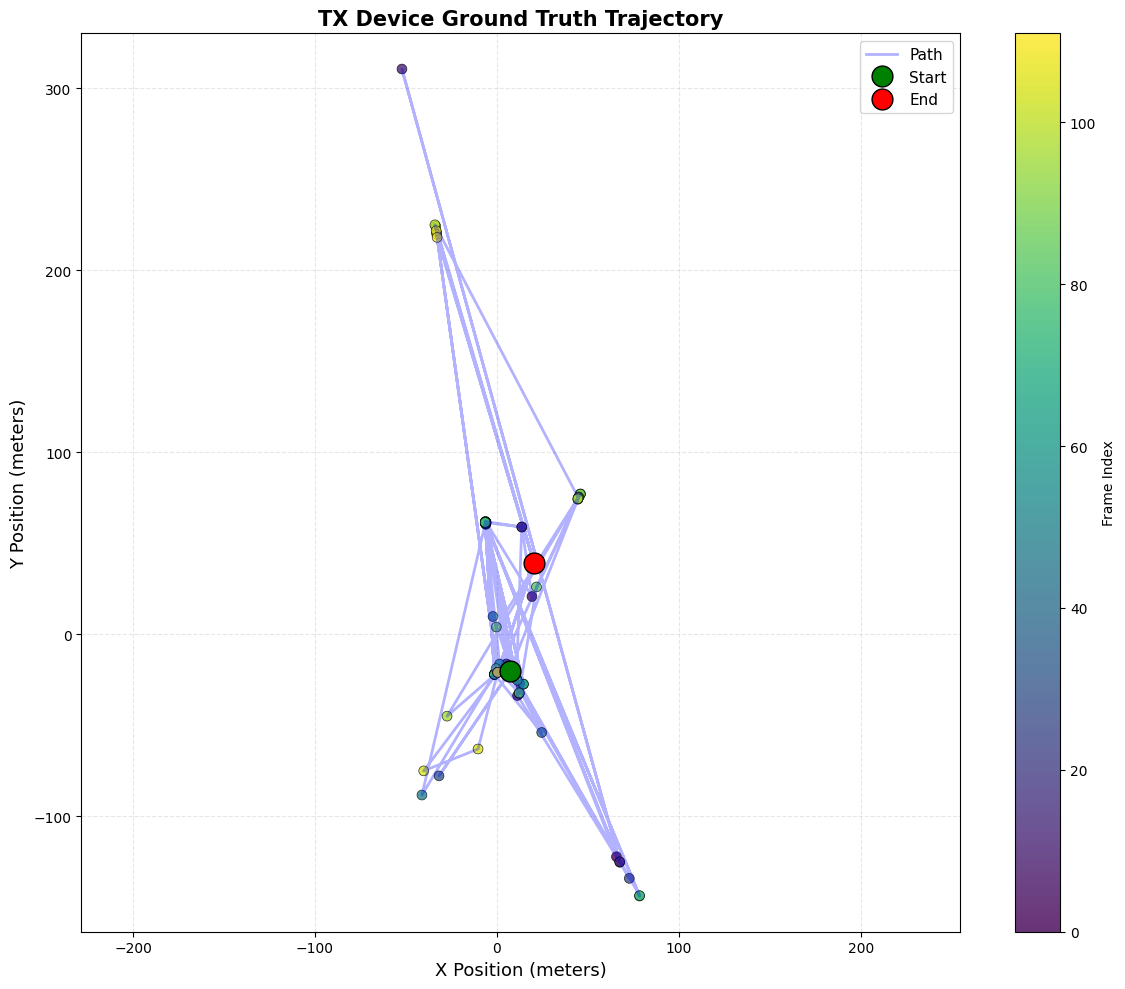


Trajectory Statistics:
  X range: -52.19 to 78.43 meters
  Y range: -143.91 to 310.65 meters
  Total distance: 8498.96 meters


In [19]:
# Extract world positions
world_pos = tracking_results['world_positions']
detected = tracking_results['detected']

# Plot trajectory
plt.figure(figsize=(12, 10))

# Plot path
plt.plot(world_pos[detected, 0], world_pos[detected, 1], 
         'b-', alpha=0.3, linewidth=2, label='Path')

# Color by time
scatter = plt.scatter(world_pos[detected, 0], world_pos[detected, 1],
                     c=np.arange(np.sum(detected)), cmap='viridis',
                     s=50, alpha=0.8, edgecolors='black', linewidths=0.5)

# Mark start and end
if np.any(detected):
    first_idx = np.where(detected)[0][0]
    last_idx = np.where(detected)[0][-1]
    plt.plot(world_pos[first_idx, 0], world_pos[first_idx, 1], 
            'go', markersize=15, label='Start', zorder=10, markeredgecolor='black')
    plt.plot(world_pos[last_idx, 0], world_pos[last_idx, 1], 
            'ro', markersize=15, label='End', zorder=10, markeredgecolor='black')

plt.xlabel('X Position (meters)', fontsize=13)
plt.ylabel('Y Position (meters)', fontsize=13)
plt.title('TX Device Ground Truth Trajectory', fontsize=15, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3, linestyle='--')
plt.axis('equal')
plt.colorbar(scatter, label='Frame Index')
plt.tight_layout()
plt.show()

# Print statistics
valid_pos = world_pos[detected]
print(f"\nTrajectory Statistics:")
print(f"  X range: {valid_pos[:, 0].min():.2f} to {valid_pos[:, 0].max():.2f} meters")
print(f"  Y range: {valid_pos[:, 1].min():.2f} to {valid_pos[:, 1].max():.2f} meters")
print(f"  Total distance: {np.sum(np.linalg.norm(np.diff(valid_pos, axis=0), axis=1)):.2f} meters")

## Step 9: Integrate with CSI/FTM Data

Pair camera ground truth with mmWave measurements for ML training or analysis.

In [ ]:
# Load CSI data
session.load_all_router_batches()
csi_data = session.get_csi_data(averaged=True)

print(f"CSI data shape: {csi_data.shape}")
print(f"Camera frames: {len(world_pos)}")

# Check alignment
if len(world_pos) == len(csi_data):
    print("\n✓ Data is aligned: 1 camera frame per CSI batch")
    
    # Create paired dataset
    paired_data = {
        'csi_magnitude': np.abs(csi_data).tolist(),
        'csi_phase': np.angle(csi_data).tolist(),
        'ground_truth_xy': world_pos.tolist(),
        'valid': detected.tolist()
    }
    
    # Save paired data
    import json
    output_file = session.session_dir / 'paired_csi_groundtruth.json'
    with open(output_file, 'w') as f:
        json.dump(paired_data, f, indent=2)
    
    print(f"✓ Paired data saved to: {output_file}")
    print(f"  - Ready for ML training!")
    print(f"  - Valid samples: {np.sum(detected)}/{len(detected)}")
else:
    print(f"\n⚠ Data size mismatch - need to determine correspondence")
    print(f"  This depends on your data collection timing.")

## Summary

You now have:

1. ✓ **Camera calibration**: Pixel → World coordinate transformation
2. ✓ **TX tracking**: Automated position detection in each frame
3. ✓ **Ground truth**: 2D XY coordinates in meters
4. ✓ **Integrated data**: Paired with CSI/FTM measurements

### Next Steps:

- **Validate**: Check a few detections manually to ensure accuracy
- **Fine-tune**: Adjust blob detection parameters (`min_area`, `max_area`) if needed
- **Alternative methods**: Try template matching or color segmentation if blob detection fails
- **ML training**: Use paired CSI + ground truth for beamforming/localization models

### Files Generated:

- `camera_calibration.json` - Homography calibration
- `tracking_results.json` - TX positions for all frames
- `paired_csi_groundtruth.json` - CSI + ground truth dataset
- Visualization plots in `plots/` folder